# 08 — Hyper-parameter Optimisation
Optuna TPE sampler (seed 42) with median pruning, maximising **validation macro-F1** (look-back 14,
horizon 1, max 20 epochs, patience 5). Budget: 24 trials for MAF-Net, 10 each for the GRU and
Transformer baselines so that baselines are tuned too. Search space:

| Parameter | Values |
|---|---|
| hidden size | 32, 64, 128 |
| layers | 1, 2 |
| dropout | 0.1, 0.2, 0.3 |
| learning rate | 3e-3, 1e-3, 3e-4 |
| batch size | 128, 256 |
| weight decay | 0, 1e-4, 1e-3 |
| loss | CE, class-weighted CE, focal (γ = 2) |
| MAF-Net only: climate encoder | GRU, LSTM, Transformer |
| MAF-Net only: d_model / heads | 32, 64, 128 / 1, 2, 4 |
| MAF-Net only: modality dropout / token self-attention | 0, 0.1, 0.2 / on, off |

Sequence length (7, 14, 30) is studied separately (it changes the sample set), see notebook 10.
The test split is not used at any point of the search.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 220)
from climatesense.utils import read_json
import platform, torch, sklearn
print("Executed:", pd.Timestamp.now().strftime("%Y-%m-%d %H:%M"), "| Python", platform.python_version(),
      "| torch", torch.__version__, "| sklearn", sklearn.__version__, "| pandas", pd.__version__)
def show(p, width=850):
    display(Image(filename=str(ROOT / p), width=width))

Executed: 2026-10-25 18:06 | Python 3.13.7 | torch 2.14.1+cu126 | sklearn 1.9.1 | pandas 3.1.0


In [2]:
for m in ["mafnet", "gru", "transformer"]:
    t = pd.DataFrame(read_json(ROOT / f"experiments/tuning/{m}_trials.json"))
    t = pd.concat([t.drop(columns="params"), pd.json_normalize(t.params)], axis=1)
    print(f"{m}: {len(t)} trials ({(t.state=='COMPLETE').sum()} complete, {(t.state=='PRUNED').sum()} pruned); best = {t.value.max():.4f}")
    display(t.sort_values("value", ascending=False).head(8).round(4))

mafnet: 28 trials (26 complete, 0 pruned); best = 0.7455


,number,value,state,run_id,n_params,hidden,layers,dropout,lr,batch_size,weight_decay,loss,encoder,d_model,heads,modality_dropout,token_self_attention
20,20,0.7455,COMPLETE,tuning-mafnet-6a82afb49f,33268.0,32,1,0.3,0.001,256,0.0000,focal,transformer,32,2,0.0,True
25,25,0.7444,COMPLETE,tuning-mafnet-9c45ae39a9,219460.0,128,1,0.3,0.001,128,0.0000,focal,transformer,32,2,0.0,False
17,17,0.7440,COMPLETE,tuning-mafnet-40937cb2a8,33268.0,32,1,0.2,0.003,256,0.0001,wce,transformer,32,2,0.0,True
10,10,0.7433,COMPLETE,tuning-mafnet-b8101e1f6e,314532.0,64,1,0.3,0.001,128,0.0000,ce,transformer,128,1,0.1,True
23,23,0.7424,COMPLETE,tuning-mafnet-dde54dcb30,314532.0,64,1,0.2,0.003,256,0.0001,focal,transformer,128,2,0.0,True
22,22,0.7420,COMPLETE,tuning-mafnet-956b517dc9,228004.0,128,1,0.2,0.003,256,0.0010,wce,transformer,32,1,0.0,True
27,27,0.7413,COMPLETE,tuning-mafnet-1f87e5142c,24724.0,32,1,0.2,0.001,256,0.0001,wce,transformer,32,2,0.0,False
16,16,0.7404,COMPLETE,tuning-mafnet-9c7f5c2738,33268.0,32,1,0.3,0.003,256,0.0001,wce,transformer,32,2,0.0,True


gru: 11 trials (10 complete, 0 pruned); best = 0.7432


,number,value,state,run_id,n_params,hidden,layers,dropout,lr,batch_size,weight_decay,loss
10,10,0.7432,COMPLETE,tuning-gru-6ed15bf700,49860.0,64,2,0.2,0.0010,128,0.0000,wce
0,0,0.7423,COMPLETE,tuning-gru-155be40f14,24900.0,64,1,0.3,0.0010,128,0.0000,wce
3,3,0.7423,COMPLETE,tuning-gru-155be40f14,24900.0,64,1,0.3,0.0010,128,0.0000,wce
1,1,0.7403,COMPLETE,tuning-gru-df23e4a212,49860.0,64,2,0.2,0.0010,128,0.0010,ce
4,4,0.7403,COMPLETE,tuning-gru-df23e4a212,49860.0,64,2,0.2,0.0010,128,0.0010,ce
8,8,0.7398,COMPLETE,tuning-gru-4d0d117c42,49860.0,64,2,0.2,0.0010,256,0.0010,wce
5,5,0.7381,COMPLETE,tuning-gru-ea8b2e3b14,8356.0,32,1,0.1,0.0003,256,0.0001,wce
9,9,0.7321,COMPLETE,tuning-gru-a81164f7d7,49860.0,64,2,0.3,0.0030,256,0.0000,ce


transformer: 10 trials (10 complete, 0 pruned); best = 0.7454


,number,value,state,run_id,n_params,hidden,layers,dropout,lr,batch_size,weight_decay,loss,heads
4,4,0.7454,COMPLETE,tuning-transformer-32809cc60b,21860,32,2,0.2,0.0030,128,0.0000,ce,1
2,2,0.7446,COMPLETE,tuning-transformer-b7724f2a04,82628,64,2,0.2,0.0030,128,0.0010,focal,4
0,0,0.7441,COMPLETE,tuning-transformer-e06bf6263e,49156,64,1,0.3,0.0010,128,0.0000,wce,2
5,5,0.7440,COMPLETE,tuning-transformer-9bb697158f,188420,128,1,0.1,0.0030,128,0.0010,wce,1
3,3,0.7439,COMPLETE,tuning-transformer-54858d4e92,49156,64,1,0.3,0.0003,256,0.0001,ce,2
1,1,0.7432,COMPLETE,tuning-transformer-3c591c130e,188420,128,1,0.2,0.0030,256,0.0000,ce,4
8,8,0.7399,COMPLETE,tuning-transformer-9ffa04aad1,320900,128,2,0.2,0.0003,128,0.0010,ce,4
7,7,0.7388,COMPLETE,tuning-transformer-98a4a21a17,13316,32,1,0.1,0.0030,128,0.0010,ce,2


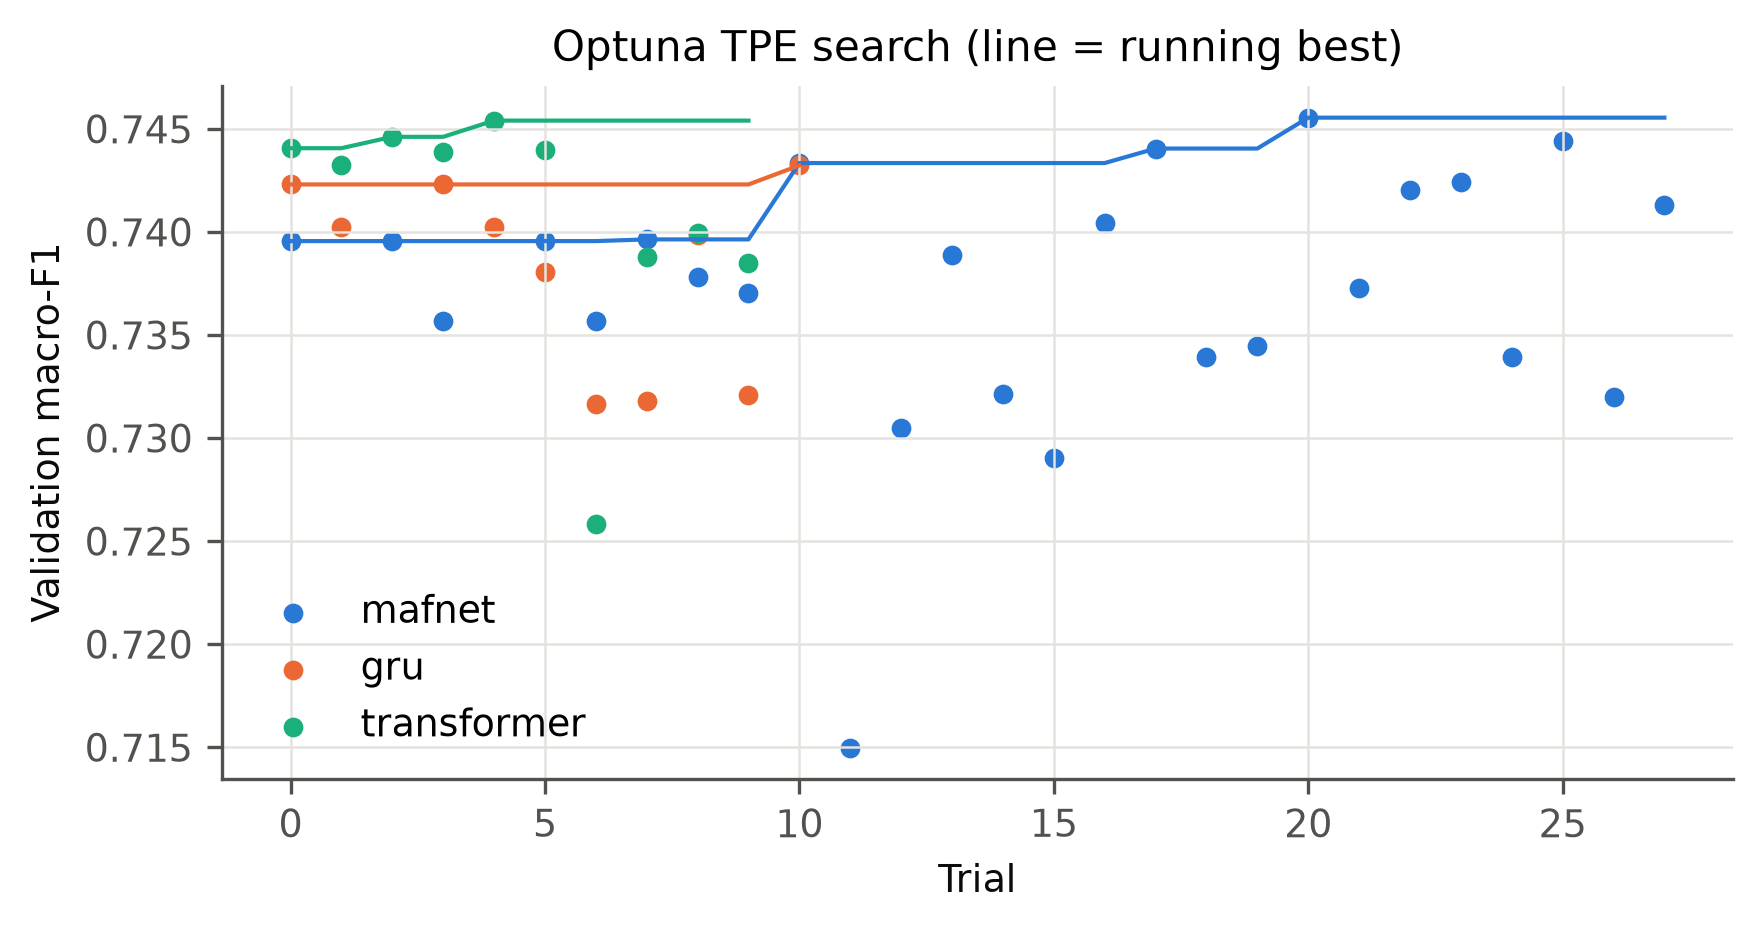

In [3]:
show("results/figures/optuna_trials.png", 700)

In [4]:
sel = read_json(ROOT / "experiments/tuning/selected_configs.json")
pd.DataFrame({k: {**v["params"], "val_macro_f1": round(v["val_macro_f1"], 4)} for k, v in sel.items()}).T

,hidden,layers,dropout,lr,batch_size,weight_decay,loss,encoder,d_model,heads,modality_dropout,token_self_attention,val_macro_f1
mafnet,32,1,0.3,0.001,256,0.0,focal,transformer,32,2,0.0,True,0.7455
gru,64,2,0.2,0.001,128,0.0,wce,NaN,NaN,NaN,NaN,NaN,0.7432
transformer,32,2,0.2,0.003,128,0.0,ce,NaN,NaN,1,NaN,NaN,0.7454


The selected configurations were then retrained for up to 40 epochs (patience 6) with five
seeds (MAF-Net, MAF-Net-concat, GRU) or three seeds (Transformer, LSTM, RNN).